[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aaxhirrr/mat-422-fall-2026/blob/main/HW3.5_3.6/HW3_5_3_6_kmeans_svm.ipynb)

# homework 3.5 and 3.6: K-means and support vector machines

Aashir Javed | MAT 422

K-means groups observations without being given class labels. A support vector machine uses labels to learn a boundary between classes. Both use geometry, but they are answering different questions. Here we can follow a small clustering example by hand, then look at margins and classification with an SVM.

The notebook covers the K-means objective, centroid updates, starting points, the choice of $k$, hard and soft SVM margins, and kernels. All data are small, made-up examples. **Runtime > Run all** in Colab runs everything without downloading data.

## setup

NumPy handles the calculations, Matplotlib draws the figures, and scikit-learn gives us a K-means comparison and the SVM solver. The clustering loop itself is short enough to write out.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

## 3.5 K-means: assigning points and moving centers

For points $\mathbf{x}_1,\ldots,\mathbf{x}_n$, we choose $k$ centers $\boldsymbol\mu_1,\ldots,\boldsymbol\mu_k$ and a cluster assignment $c_i$ for each point. K-means minimizes the sum of squared distances within the clusters:

$$J=\sum_{i=1}^n\|\mathbf{x}_i-\boldsymbol\mu_{c_i}\|^2.$$

The two updates are straightforward:

1. Assign each point to its nearest center: $c_i=\arg\min_j\|\mathbf{x}_i-\boldsymbol\mu_j\|^2$.
2. Replace each center with the mean of the points assigned to it: $\boldsymbol\mu_j=\frac{1}{|C_j|}\sum_{i\in C_j}\mathbf{x}_i$.

Why the mean? For a fixed nonempty cluster, differentiating its squared-distance sum gives $2|C_j|\boldsymbol\mu_j-2\sum_{i\in C_j}\mathbf{x}_i$. Setting that to zero gives the mean. The assignment step and the mean update each cannot increase $J$.

I use twelve points so the final centers are easy to check. The initial centers are deliberately unevenly placed. The loop records the objective after assigning points, and stops when the mean update no longer moves the centers. If a cluster becomes empty, it keeps its old center for that update.

final centers:
 [[-3.5 -1.5]
 [ 0.5  3.5]
 [ 4.5 -1.5]]
points in each cluster: [4 4 4]
objective after each assignment: [170.   26.5   6. ]


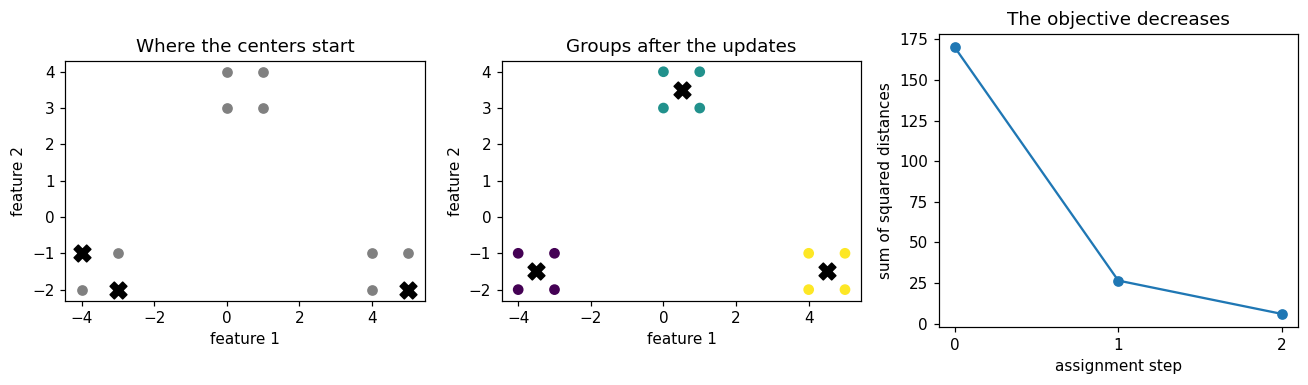

In [2]:
points = np.array([
    [-4, -2], [-3, -2], [-4, -1], [-3, -1],
    [0, 3], [1, 3], [0, 4], [1, 4],
    [4, -2], [5, -2], [4, -1], [5, -1]
], dtype=float)

def kmeans_steps(X, starting_centers, max_steps=50):
    centers = starting_centers.copy()
    history = []
    for step in range(max_steps):
        distances = ((X[:, None, :] - centers[None, :, :])**2).sum(axis=2)
        labels = distances.argmin(axis=1)
        history.append(distances[np.arange(len(X)), labels].sum())
        new_centers = centers.copy()
        for j in range(len(centers)):
            members = X[labels == j]
            if len(members):
                new_centers[j] = members.mean(axis=0)
        if np.allclose(new_centers, centers, atol=1e-10, rtol=0):
            return centers, labels, np.array(history)
        centers = new_centers
    raise RuntimeError("The centers still moved at the step limit.")

starting_centers = points[[1, 2, 9]]
centers, clusters, objective = kmeans_steps(points, starting_centers)
print("final centers:\n", centers)
print("points in each cluster:", np.bincount(clusters, minlength=3))
print("objective after each assignment:", objective)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
axes[0].scatter(points[:, 0], points[:, 1], color="gray", label="points")
axes[0].scatter(starting_centers[:, 0], starting_centers[:, 1],
                marker="X", s=120, color="black", label="starting centers")
axes[0].set_title("Where the centers start")
axes[1].scatter(points[:, 0], points[:, 1], c=clusters, cmap="viridis")
axes[1].scatter(centers[:, 0], centers[:, 1], marker="X", s=120,
                color="black", label="final centers")
axes[1].set_title("Groups after the updates")
for ax in axes[:2]:
    ax.set(xlabel="feature 1", ylabel="feature 2", aspect="equal")
axes[2].plot(range(len(objective)), objective, "o-")
axes[2].set(xlabel="assignment step", ylabel="sum of squared distances", title="The objective decreases")
axes[2].set_xticks(range(len(objective)))
fig.tight_layout()
plt.show()

The objective falls from $170$ to $26.5$ and then to $6$. The centers end up at $(-3.5,-1.5)$, $(0.5,3.5)$, and $(4.5,-1.5)$, with four points in each cluster. Each point is half a unit from its center in both coordinates, so its squared distance is $0.5$. Twelve contributions of $0.5$ give the printed total of $6$.

### starting points and the choice of $k$

Decreasing the objective does not guarantee the best possible clustering. Both the assignments and centers are unknown, so this is not a jointly convex optimization problem. We can start the same loop elsewhere and get stuck at a worse solution.

The next cell compares that start with scikit-learn's K-means++ initialization and ten restarts. K-means++ spreads out the initial centers, and restarts give the solver more chances to find a lower objective. Neither is a general guarantee of the global minimum.

We also vary $k$. The elbow plot asks where extra clusters stop making a large difference. The best achievable objective cannot increase as $k$ grows, so choosing the smallest objective alone would keep favoring more clusters. An elbow is a useful clue, not a proof of the correct number of groups.

our first start: 6.0
the other start: 87.0
K-means++ with 10 starts: 6.0
k values: [1 2 3 4 5 6]
squared-distance totals: [200.67  88.     6.     5.     4.     3.  ]


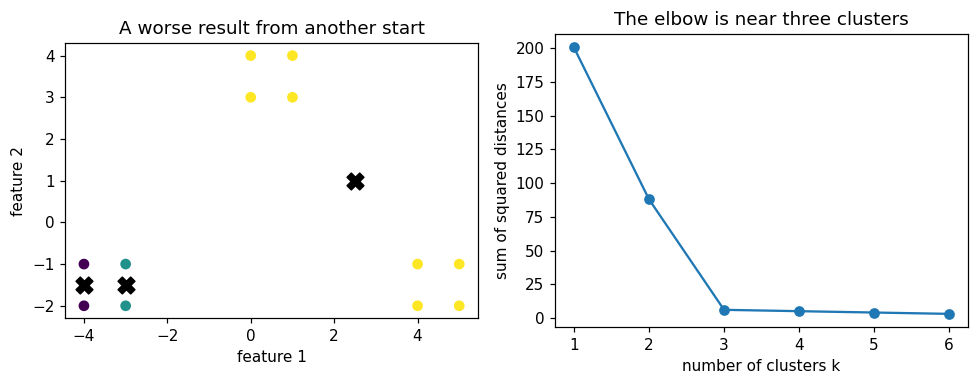

In [3]:
poor_centers, poor_clusters, poor_objective = kmeans_steps(points, points[[0, 1, 4]])
library_kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=422).fit(points)
print(f"our first start: {objective[-1]:.1f}")
print(f"the other start: {poor_objective[-1]:.1f}")
print(f"K-means++ with 10 starts: {library_kmeans.inertia_:.1f}")

k_values = np.arange(1, 7)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=int(k), n_init=10, random_state=422).fit(points)
    inertias.append(model.inertia_)
print("k values:", k_values)
print("squared-distance totals:", np.round(inertias, 2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].scatter(points[:, 0], points[:, 1], c=poor_clusters, cmap="viridis")
axes[0].scatter(poor_centers[:, 0], poor_centers[:, 1], color="black", marker="X", s=120)
axes[0].set(xlabel="feature 1", ylabel="feature 2", aspect="equal", title="A worse result from another start")
axes[1].plot(k_values, inertias, "o-")
axes[1].set(xlabel="number of clusters k", ylabel="sum of squared distances", title="The elbow is near three clusters")
axes[1].set_xticks(k_values)
fig.tight_layout()
plt.show()

The other start stops at $87$: it splits the left group into two clusters and combines the upper and right groups. Its centers have stopped moving, but that does not make the grouping the best one. The library result agrees with the lower objective of $6$. Cluster numbers themselves have no meaning, so a different numbering would not count as a different answer.

The elbow near $k=3$ matches the three compact groups we drew. Real data may not have an obvious elbow. K-means also favors compact groups under Euclidean distance and can be affected by outliers. Feature units matter: a coordinate measured in thousands can dominate one measured in decimals. These two coordinates use comparable scales; with unlike units, we would consider standardizing them before computing distances.

## 3.6 support vector machines: the margin

Now the points have labels $y_i\in\{-1,+1\}$. A linear SVM uses the score $f(\mathbf{x})=\mathbf{w}^T\mathbf{x}+b$, predicting a class from its sign. The decision boundary is $f(\mathbf{x})=0$.

For separable data, the hard-margin formulation is

$$\min_{\mathbf{w},b}\frac12\|\mathbf{w}\|^2\quad\text{subject to}\quad y_i(\mathbf{w}^T\mathbf{x}_i+b)\ge1.$$

The boundary-to-margin distance is $1/\|\mathbf{w}\|$, so the full gap between the $f=-1$ and $f=1$ lines is $2/\|\mathbf{w}\|$. Minimizing the squared norm maximizes that gap. The nearest points that constrain it are support vectors.

For this small example, the nearest opposite classes have first coordinates $-1$ and $1$. We should get a boundary at $x_1=0$ and a full margin width of $2$. `SVC` uses a soft-margin solver; a large $C$ recovers the hard-margin solution here, which we check numerically rather than assume.

weights: [1. 0.] intercept: -0.0
signed scores y*f(x): [2. 2. 1. 1. 1. 1. 2. 2.]
support-vector coordinates:
 [[-1.  1.]
 [ 1.  1.]]
full margin width: 2.0000


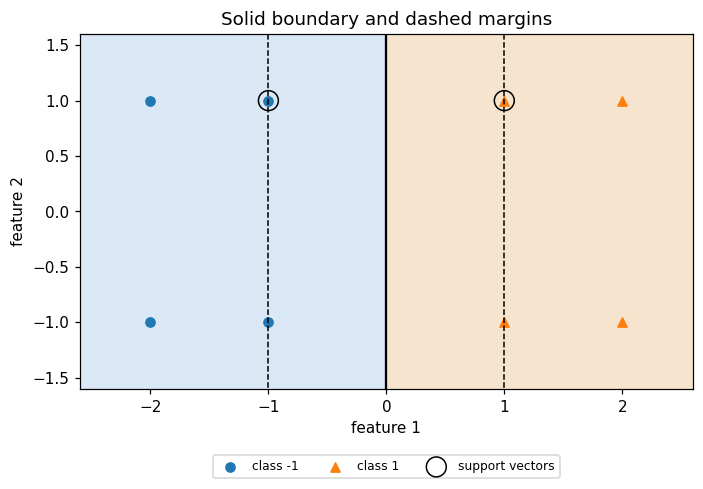

In [4]:
separable_X = np.array([[-2, -1], [-2, 1], [-1, -1], [-1, 1],
                        [1, -1], [1, 1], [2, -1], [2, 1]], dtype=float)
separable_y = np.array([-1, -1, -1, -1, 1, 1, 1, 1])
hard_model = SVC(kernel="linear", C=1000, tol=1e-8).fit(separable_X, separable_y)
w = hard_model.coef_[0]
b = hard_model.intercept_[0]
signed_margins = separable_y * hard_model.decision_function(separable_X)
margin_width = 2 / np.linalg.norm(w)
print("weights:", w, "intercept:", b)
print("signed scores y*f(x):", signed_margins)
print("support-vector coordinates:\n", hard_model.support_vectors_)
print(f"full margin width: {margin_width:.4f}")

def draw_svm(ax, model, X, y, title):
    x1 = np.linspace(X[:, 0].min()-0.6, X[:, 0].max()+0.6, 180)
    x2 = np.linspace(X[:, 1].min()-0.6, X[:, 1].max()+0.6, 180)
    xx, yy = np.meshgrid(x1, x2)
    score = model.decision_function(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)
    ax.contourf(xx, yy, score >= 0, levels=[-0.5, 0.5, 1.5],
                colors=["#c9dff0", "#f4d9ba"], alpha=0.7)
    ax.contour(xx, yy, score, levels=[-1, 0, 1], colors="black",
               linestyles=["--", "-", "--"], linewidths=[1, 1.5, 1])
    for label, color, marker in [(-1, "tab:blue", "o"), (1, "tab:orange", "^")]:
        selected = y == label
        ax.scatter(X[selected, 0], X[selected, 1], color=color, marker=marker, label=f"class {label}")
    ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
               s=170, facecolors="none", edgecolors="black", label="support vectors")
    ax.set(xlabel="feature 1", ylabel="feature 2", title=title)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
draw_svm(ax, hard_model, separable_X, separable_y, "Solid boundary and dashed margins")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
fig.tight_layout()
plt.show()

The fitted weights are $(1,0)$ and the intercept is zero, so the second coordinate does not affect this boundary. The signed scores are at least $1$, and the full margin width is $2$, as expected. Black circles mark the solver's support vectors. In a degenerate example, a point can lie on a margin without receiving a nonzero dual coefficient, so the solver does not have to mark every tied point.

### allowing a point inside the margin

Perfect separation is not always possible. Soft-margin SVM introduces slack variables $\xi_i$:

$$\min_{\mathbf{w},b,\boldsymbol\xi}\frac12\|\mathbf{w}\|^2+C\sum_i\xi_i,\qquad y_i f(\mathbf{x}_i)\ge1-\xi_i,\quad\xi_i\ge0.$$

For fixed scores, the smallest feasible slack is the hinge loss $\xi_i=\max(0,1-y_i f(\mathbf{x}_i))$. A point can be correctly classified and still have positive hinge loss if it is inside the margin. A negative signed score means a misclassification.

A larger $C$ puts more weight on violations relative to the squared norm; a smaller $C$ allows more slack in exchange for a smaller norm. Larger $C$ does not guarantee better predictions on new data.

We can add a positive point at $(-1.5,0)$, inside the negative group's convex hull. A straight line cannot correctly separate all these labels. The next comparison uses fixed $C$ values to show the tradeoff on the same training data.

C      margin width    total hinge loss    training mistakes
0.1        4.0000            3.7500      1
1          2.0000            2.5000      1
10         2.0000            2.5000      1


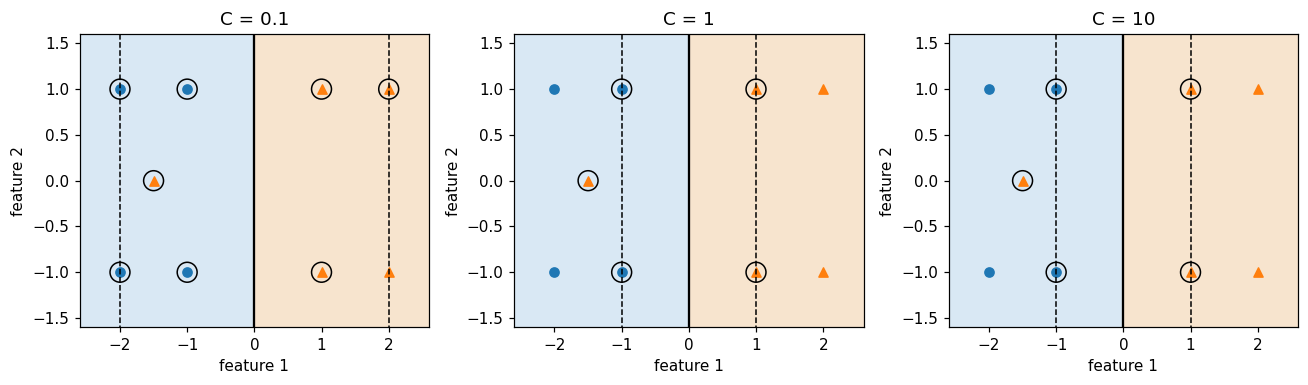

In [5]:
overlap_X = np.vstack([separable_X, [-1.5, 0]])
overlap_y = np.append(separable_y, 1)
soft_models = []
soft_slacks = []
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
print("C      margin width    total hinge loss    training mistakes")
for ax, C in zip(axes, [0.1, 1, 10]):
    model = SVC(kernel="linear", C=C, tol=1e-8).fit(overlap_X, overlap_y)
    slack = np.maximum(0, 1-overlap_y*model.decision_function(overlap_X))
    width = 2 / np.linalg.norm(model.coef_[0])
    mistakes = np.sum(model.predict(overlap_X) != overlap_y)
    print(f"{C:<5g}  {width:10.4f}    {slack.sum():14.4f}    {mistakes:3d}")
    soft_models.append(model)
    soft_slacks.append(slack)
    draw_svm(ax, model, overlap_X, overlap_y, f"C = {C:g}")
fig.tight_layout()
plt.show()

The added positive point stays on the negative side in this comparison. At $C=0.1$, the full margin width is $4$ and total hinge loss is $3.75$. At $C=1$ and $C=10$, the width is $2$ and hinge loss is $2.5$. The lower-$C$ model accepts more hinge loss and a wider margin, while all three make one training mistake. Changing a parameter does not require the fitted result to change every time. These are training comparisons to explain the objective, not evidence that one $C$ will perform best on future data.

### a kernel when a straight line is not enough

The dual form expresses the fitted score using training points:

$$f(\mathbf{x})=\sum_{i\in SV}\alpha_i y_i K(\mathbf{x}_i,\mathbf{x})+b.$$

For soft margins, $0\le\alpha_i\le C$ and $\sum_i\alpha_i y_i=0$. Only the nonzero coefficients contribute. A linear kernel uses a dot product. An RBF kernel uses

$$K(\mathbf{x},\mathbf{z})=e^{-\gamma\|\mathbf{x}-\mathbf{z}\|^2}.$$

The kernel acts as a dot product in an implicit feature space, allowing a nonlinear boundary in the original coordinates. Larger $\gamma$ makes similarity drop more quickly with distance, so the boundary can become more local and potentially overfit.

We can compare linear and RBF SVMs on two curved groups. The split is made first, and each pipeline fits its scaler using only the training observations. Both use fixed settings chosen for this demonstration, so the test set is not used to select $C$ or $\gamma$.

training points: 168 test points: 72
linear test accuracy: 0.8472
confusion matrix (actual rows, predicted columns; order -1, +1):
[[32  4]
 [ 7 29]]
RBF test accuracy: 0.9583
confusion matrix (actual rows, predicted columns; order -1, +1):
[[35  1]
 [ 2 34]]


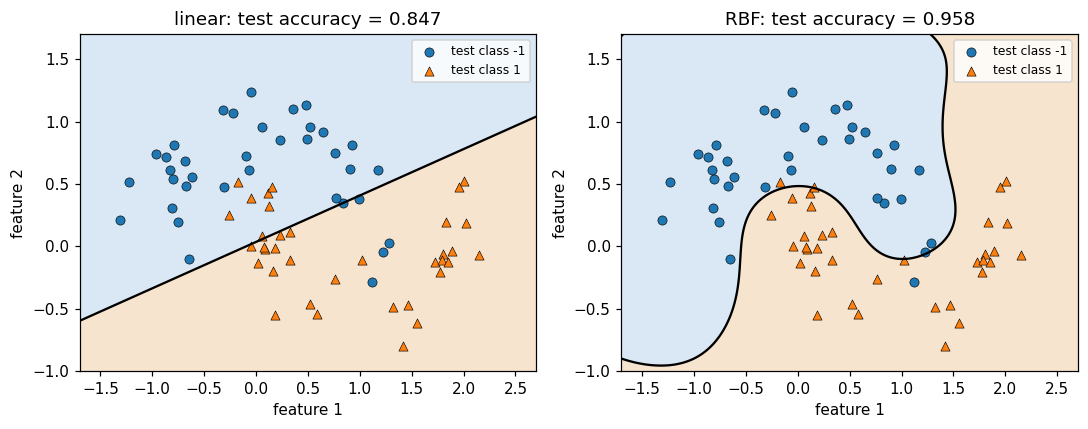

In [6]:
moon_X, moon_labels = make_moons(n_samples=240, noise=0.18, random_state=422)
moon_y = 2*moon_labels - 1
train_ids, test_ids = train_test_split(np.arange(len(moon_y)), test_size=0.3,
                                      stratify=moon_y, random_state=422)
X_train, X_test = moon_X[train_ids], moon_X[test_ids]
y_train, y_test = moon_y[train_ids], moon_y[test_ids]
models = {
    "linear": make_pipeline(StandardScaler(), SVC(kernel="linear", C=1)),
    "RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1, gamma=1))
}
xx, yy = np.meshgrid(np.linspace(-1.7, 2.7, 220), np.linspace(-1.0, 1.7, 180))
grid = np.column_stack([xx.ravel(), yy.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
predictions = {}
print("training points:", len(y_train), "test points:", len(y_test))
for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    predictions[name] = predicted
    accuracy = accuracy_score(y_test, predicted)
    print(f"{name} test accuracy: {accuracy:.4f}")
    print("confusion matrix (actual rows, predicted columns; order -1, +1):")
    print(confusion_matrix(y_test, predicted, labels=[-1, 1]))
    score = model.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx, yy, score >= 0, levels=[-0.5, 0.5, 1.5],
                colors=["#c9dff0", "#f4d9ba"], alpha=0.7)
    ax.contour(xx, yy, score, levels=[0], colors="black")
    for label, color, marker in [(-1, "tab:blue", "o"), (1, "tab:orange", "^")]:
        selected = y_test == label
        ax.scatter(X_test[selected, 0], X_test[selected, 1], color=color,
                   marker=marker, edgecolors="black", linewidths=0.4, label=f"test class {label}")
    ax.set(xlabel="feature 1", ylabel="feature 2", title=f"{name}: test accuracy = {accuracy:.3f}")
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The linear boundary cuts across the curved groups, while the RBF boundary bends between them. The linear model gets $61$ of the $72$ test labels right, about $84.7\%$. The RBF model gets $69$ right, about $95.8\%$, with one negative example predicted positive and two positive examples predicted negative. A curved boundary helps on this constructed example; that does not make the RBF kernel the better choice for every dataset. In an actual model-selection task, we would tune $C$ and $\gamma$ on separate validation data or within cross-validation.

An SVM decision score is not a probability. Its sign gives the predicted class here, and its magnitude describes position relative to the learned boundary. Probability estimates would require an additional calibration procedure.

## checking the calculations

We can verify the centroid means and distance totals, then compare the SVM's linear and kernel score formulas with the library output. I also check that the training/test split stays separate and that the scalers only learned from the training points. These checks concern the calculations, not a guarantee that one model always wins.

In [7]:
centroid_means = np.array([points[clusters == j].mean(axis=0) for j in range(3)])
distance_total = np.sum((points-centers[clusters])**2)
recovered_w = hard_model.dual_coef_[0] @ hard_model.support_vectors_
rbf_scaler = models["RBF"].named_steps["standardscaler"]
rbf_model = models["RBF"].named_steps["svc"]
scaled_test = rbf_scaler.transform(X_test)
kernel_values = np.exp(-rbf_model.gamma *
                       ((scaled_test[:, None, :]-rbf_model.support_vectors_[None, :, :])**2).sum(axis=2))
manual_rbf_scores = kernel_values @ rbf_model.dual_coef_[0] + rbf_model.intercept_[0]
checks = {
    "centers equal their cluster means": np.allclose(centers, centroid_means),
    "distance sum matches the objective": np.isclose(distance_total, objective[-1]),
    "K-means objective does not increase": np.all(np.diff(objective) <= 1e-10),
    "library finds the same lower objective": np.isclose(library_kmeans.inertia_, objective[-1]),
    "a different start gives a worse result": poor_objective[-1] > objective[-1],
    "hard-margin constraints hold": np.all(signed_margins >= 1-1e-6),
    "full margin width is two": np.isclose(margin_width, 2),
    "support-vector formula recovers w": np.allclose(recovered_w, w),
    "soft-margin slacks satisfy constraints": all(np.all(overlap_y*m.decision_function(overlap_X) >= 1-s-1e-8)
                                                 for m, s in zip(soft_models, soft_slacks)),
    "train and test IDs are disjoint": len(np.intersect1d(train_ids, test_ids)) == 0,
    "scalers use the training mean": all(np.allclose(m.named_steps["standardscaler"].mean_, X_train.mean(axis=0))
                                         for m in models.values()),
    "RBF score matches the kernel sum": np.allclose(manual_rbf_scores, models["RBF"].decision_function(X_test)),
    "confusion matrices count all test points": all(confusion_matrix(y_test, p).sum() == len(y_test)
                                                 for p in predictions.values())
}
for label, passed in checks.items():
    print(f"{label}: {bool(passed)}")
assert all(checks.values()), "one of the checks needs another look"

centers equal their cluster means: True
distance sum matches the objective: True
K-means objective does not increase: True
library finds the same lower objective: True
a different start gives a worse result: True
hard-margin constraints hold: True
full margin width is two: True
support-vector formula recovers w: True
soft-margin slacks satisfy constraints: True
train and test IDs are disjoint: True
scalers use the training mean: True
RBF score matches the kernel sum: True
confusion matrices count all test points: True


## what I took from this

For K-means, a lower squared-distance total tells us the groups are more compact, but the result still depends on the starting centers, scaling, and choice of $k$. Watching the objective decrease was useful because it also showed the limitation: the worse start decreased its objective too.

For SVM, the margin gives a geometric reason for the objective. Slack makes that idea usable when labels overlap, and a kernel lets the boundary curve. We can compare the resulting predictions on held-out labels rather than judging the training plot alone.

The notebook includes both assigned topics, formulas, examples, saved outputs, and numerical checks. Before submitting, rerun it from the top, review the explanations, and check that the Open in Colab button works from GitHub. The point coordinates and starting centers are also easy to change if we want to see how the clustering responds.

## references

- [MAT 422 section 3.5 and 3.6 guidance](https://github.com/DynamicLLM/MAT422/blob/main/Skills/Student-Home-Work-Skills-Pack/mat422-section-3-5-3-6-kmeans-svm/references/section-3-5-3-6-guidance.md)
- [scikit-learn: K-means](https://scikit-learn.org/stable/modules/clustering.html#k-means)
- [scikit-learn: support vector machines](https://scikit-learn.org/stable/modules/svm.html)

- AI use note: I had help from Codex in refining the code (not completely writing it), refining the latex of the report, and pushing it to GitHub. Other than that, the intial psuedocode/boilerplates, logic, and the report is still drafted by me. I ran every cell and reviewed the math and explanations before submitting.